# Transmon: theory, spectrum and electrostatic model
EC3104 Group Project

This notebook presents our study of the transmon qubit. We start from the example parameters **EJ/h = 15 GHz, EC/h = 0.30 GHz, ng = 0 and ncut = 30** and extend them into a reproducible study. Run the cells from top to bottom. Saved outputs are included.

**What we demonstrate:** charge-basis diagonalization, transition frequencies, anharmonicity, wavefunctions, charge sensitivity, parameter and cutoff sweeps, a 2D electrostatic teaching model, the capacitance-to-EC-to-f01 bridge on a synthetic two-pad circuit, and a CPW readout resonator as a transmission-line link.

## Run guide
Use a Python 3 kernel with NumPy, SciPy, Matplotlib, scqubits 4.3.1 and IPython. If scqubits is missing, run `%pip install scqubits==4.3.1` in a new cell, restart the kernel and run all cells. Use `python -m pip install jupyterlab` in the activated environment if Jupyter is missing. No paid software is needed for the executed sections.

Sections: 1. Theory · 2. Base calculation · 3. Validation and plots · 4. Parameter study · 5. Circuit parameters · 6. 2D electrostatics · 7. Capacitance extraction to EC (7b: CPW resonator) · 8. Summary and sources.

## 1. Theory and units
A Josephson junction supplies a nonlinear inductive element, shunted by a capacitance. A harmonic LC oscillator has equal level spacing; the Josephson cosine makes the spacing unequal so the lowest two states can be addressed as a qubit.

$$H=4E_C(\hat n-n_g)^2-E_J\cos\hat\varphi,\qquad [\hat\varphi,\hat n]=i.$$

In charge basis, $n$ counts Cooper pairs. The diagonal entries are $4E_C(n-n_g)^2$ and the nearest-neighbor entries are $-E_J/2$. The basis is $n=-n_{cut},\ldots,n_{cut}$, of size $2n_{cut}+1$. `truncated_dim=6` is a retained low-energy dimension for later composite-system work; it does not replace the charge-basis cutoff.

Throughout our quantum calculation, `EJ` and `EC` mean **energy divided by Planck's constant h in GHz**, not angular frequency and not joules. Therefore differences of computed eigenvalues are frequencies in GHz.

$$E_C=\frac{e^2}{2C_\Sigma},\quad E_J=\frac{\Phi_0 I_c}{2\pi},\quad
L_J=\frac{(\Phi_0/2\pi)^2}{E_J},\quad \Phi_0=\frac{h}{2e}.$$

For $E_J/E_C\gg1$, the leading estimates are
$$f_{01}\simeq\sqrt{8(E_J/h)(E_C/h)}-E_C/h,\qquad \alpha=f_{12}-f_{01}\simeq-E_C/h.$$
These are approximations, not substitutes for diagonalization. Large $E_J/E_C$ suppresses charge dispersion but reduces relative anharmonicity. We do not supply a noise spectrum here, so we make no $T_1$ or $T_2$ claim.

## 2. Base calculation
The five base calculation cells are retained below, including their cell IDs. Their saved outputs are regenerated in a clean kernel; the duplicate import is harmless.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import scqubits as scq
from mpl_toolkits.mplot3d import Axes3D

print("NumPy:", np.__version__)
print("scqubits:", scq.__version__)
print("Matplotlib 3D works!")

NumPy: 2.2.6
scqubits: 4.3.1
Matplotlib 3D works!


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scqubits as scq

print("scqubits version:", scq.__version__)

scqubits version: 4.3.1


In [3]:
transmon = scq.Transmon(
    EJ=15.0,       # Josephson energy divided by h, in GHz
    EC=0.30,       # Charging energy divided by h, in GHz
    ng=0.0,        # Offset charge, in Cooper-pair units
    ncut=30,       # Charge-basis cutoff
    truncated_dim=6
)

print(transmon)

Transmon------------| [Transmon_1]
                    | EJ: 15.0
                    | EC: 0.3
                    | ng: 0.0
                    | ncut: 30
                    | truncated_dim: 6
                    |
                    | dim: 61



In [4]:
energies = transmon.eigenvals(evals_count=6)

print("Energy levels relative to the ground state:")
for i, energy in enumerate(energies):
    print(f"E{i} - E0 = {energy - energies[0]:.6f} GHz")

Energy levels relative to the ground state:
E0 - E0 = 0.000000 GHz
E1 - E0 = 5.682576 GHz
E2 - E0 = 11.020384 GHz
E3 - E0 = 15.972981 GHz
E4 - E0 = 20.418606 GHz
E5 - E0 = 24.617355 GHz


In [5]:
f01 = energies[1] - energies[0]
f12 = energies[2] - energies[1]

anharmonicity = f12 - f01

print(f"f01 = {f01:.6f} GHz")
print(f"f12 = {f12:.6f} GHz")
print(f"Anharmonicity = {anharmonicity:.6f} GHz")
print(f"Anharmonicity = {anharmonicity * 1000:.2f} MHz")

f01 = 5.682576 GHz
f12 = 5.337809 GHz
Anharmonicity = -0.344767 GHz
Anharmonicity = -344.77 MHz


In [6]:
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
import sys, scipy, matplotlib
from scipy.constants import elementary_charge as e, h, epsilon_0
from IPython.display import display, Markdown
from pathlib import Path
import csv

plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.22, "font.size": 11})
TEAL, INK, RED = "#397f70", "#251f21", "#bd3c3c"
print("Execution environment:")
print("Python", sys.version.split()[0], "| NumPy", np.__version__,
      "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__,
      "| scqubits", scq.__version__)
EJ, EC, ng, ncut = transmon.EJ, transmon.EC, transmon.ng, transmon.ncut
assert np.isfinite(energies).all() and np.all(np.diff(energies) > 0)

Execution environment:
Python 3.10.12 | NumPy 2.2.6 | SciPy 1.15.3 | Matplotlib 3.10.9 | scqubits 4.3.1


## 3. Validation and visualization
### Independent Hamiltonian check
We build the same tridiagonal Hamiltonian with NumPy. Agreement checks units, signs, basis size and the library call; it is not an experimental validation.

In [7]:
charges = np.arange(-ncut, ncut + 1)
H_charge = np.diag(4 * EC * (charges - ng)**2)
H_charge += np.diag(np.full(2*ncut, -EJ/2), 1)
H_charge += np.diag(np.full(2*ncut, -EJ/2), -1)
manual_evals, manual_vecs = np.linalg.eigh(H_charge)
max_error = np.max(np.abs(manual_evals[:6] - energies))
print(f"Charge-basis dimension: {H_charge.shape[0]}")
print(f"Largest library/manual difference: {max_error:.3e} GHz")
assert np.allclose(manual_evals[:6], energies, atol=1e-9, rtol=0)
approx_f01 = np.sqrt(8 * EJ * EC) - EC
print(f"EJ/EC = {EJ/EC:.1f}")
print(f"Approximate f01: {approx_f01:.6f} GHz; exact: {f01:.6f} GHz")
print(f"Approximate alpha: {-EC*1000:.2f} MHz; exact: {anharmonicity*1000:.2f} MHz")
print(f"f01 approximation error: {100*(approx_f01/f01-1):.3f}%")

Charge-basis dimension: 61
Largest library/manual difference: 9.059e-14 GHz
EJ/EC = 50.0
Approximate f01: 5.700000 GHz; exact: 5.682576 GHz
Approximate alpha: -300.00 MHz; exact: -344.77 MHz
f01 approximation error: 0.307%


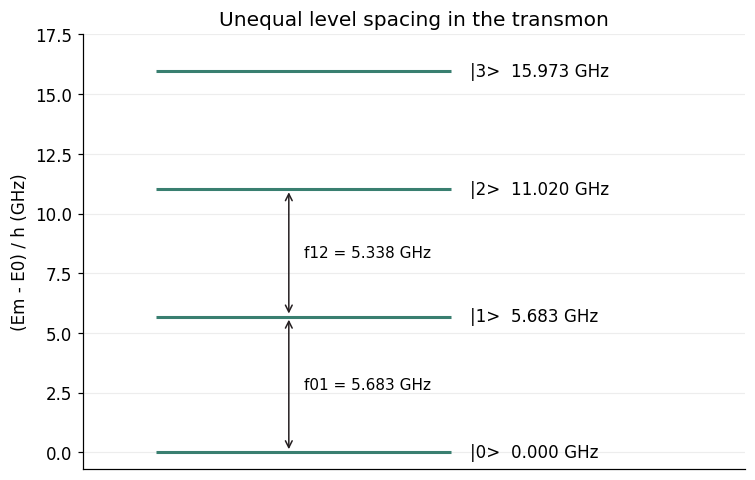

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, val in enumerate(energies[:4] - energies[0]):
    ax.hlines(val, 0.15, 0.75, color=TEAL, linewidth=2)
    ax.text(0.79, val, f"|{i}>  {val:.3f} GHz", va="center")
for bottom, top, label in [(0, energies[1]-energies[0], f"f01 = {f01:.3f} GHz"),
                          (energies[1]-energies[0], energies[2]-energies[0], f"f12 = {f12:.3f} GHz")]:
    ax.annotate("", xy=(0.42, top), xytext=(0.42, bottom),
                arrowprops=dict(arrowstyle="<->", color=INK))
    ax.text(0.45, (bottom+top)/2, label, va="center", fontsize=10)
ax.set(xlim=(0, 1.35), ylim=(-0.7, 17.5), ylabel="(Em - E0) / h (GHz)",
       title="Unequal level spacing in the transmon")
ax.set_xticks([]); fig.tight_layout(); plt.show()

### Charge-basis wavefunctions
The squared coefficients are probabilities for a charge-basis measurement. They are not spatial electron densities on the capacitor pads.

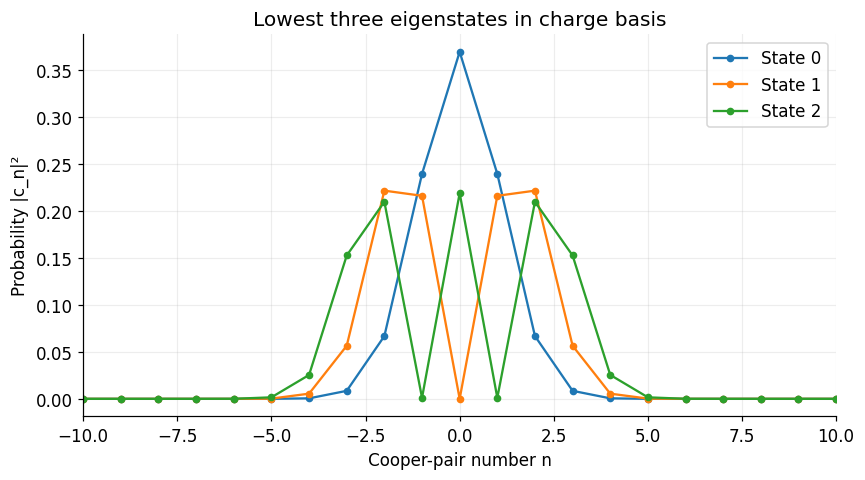

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for level in range(3):
    ax.plot(charges, np.abs(manual_vecs[:, level])**2, "o-", ms=4, label=f"State {level}")
ax.set(xlim=(-10, 10), xlabel="Cooper-pair number n", ylabel="Probability |c_n|²",
       title="Lowest three eigenstates in charge basis")
ax.legend(); fig.tight_layout(); plt.show()
assert np.allclose(np.sum(np.abs(manual_vecs[:, :3])**2, axis=0), 1)

### Charge-cutoff convergence
We compare the transition frequencies with a larger ncut = 50 reference. This validates numerical truncation only. It does not validate any EM geometry.

In [10]:
def transitions(ej=EJ, ec=EC, offset=0.0, cutoff=30):
    vals = scq.Transmon(EJ=ej, EC=ec, ng=offset, ncut=cutoff, truncated_dim=6).eigenvals(evals_count=3)
    return vals[1]-vals[0], vals[2]-vals[1]-(vals[1]-vals[0])

ref_f, ref_a = transitions(cutoff=50)
cutoffs = [6, 8, 10, 15, 20, 30, 40]
print("ncut    f01 (GHz)     alpha (MHz)     |df01| vs ncut50 (Hz)")
cutoff_errors = []
for cut in cutoffs:
    f, a = transitions(cutoff=cut)
    err = abs(f-ref_f)*1e9
    cutoff_errors.append(err)
    print(f"{cut:4d}    {f:11.8f}   {a*1000:12.6f}   {err:14.6g}")
assert abs(f01-ref_f)*1e9 < 1.0
print("PASS: original ncut=30 changes f01 by less than 1 Hz relative to ncut=50.")

ncut    f01 (GHz)     alpha (MHz)     |df01| vs ncut50 (Hz)
   6     5.68258529    -344.696507          9608.32
   8     5.68257568    -344.766902         0.685445
  10     5.68257568    -344.766909      0.000285993
  15     5.68257568    -344.766909      0.000276223
  20     5.68257568    -344.766909      0.000304645
  30     5.68257568    -344.766909      0.000406786
  40     5.68257568    -344.766909      0.000171418
PASS: original ncut=30 changes f01 by less than 1 Hz relative to ncut=50.


## 4. Parameter studies
### Offset charge
At fixed EC, we compare EJ/EC = 5 (charge-sensitive regime) with the base ratio 50. A full period is ng from 0 to 1. We plot the frequency shift rather than the large carrier frequency to make dispersion visible. The sampled peak-to-peak range is a numerical measure, not a measured noise amplitude.

EJ/EC=5: sampled peak-to-peak f01 dispersion = 321987136.952 Hz
EJ/EC=50: sampled peak-to-peak f01 dispersion = 11889.089 Hz


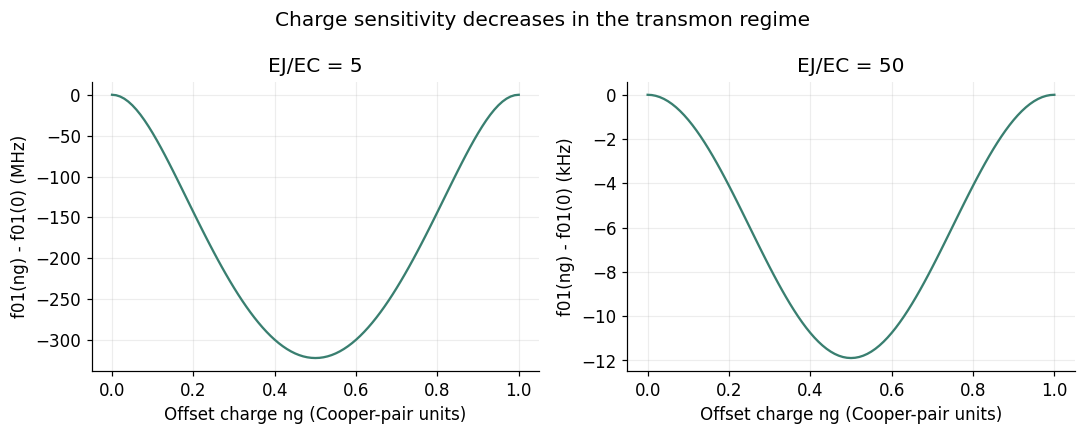

In [11]:
ng_values = np.linspace(0, 1, 101)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
dispersions = {}
for ax, ratio in zip(axes, [5, 50]):
    fs = np.array([transitions(ej=ratio*EC, offset=g)[0] for g in ng_values])
    dispersion_hz = np.ptp(fs)*1e9
    dispersions[ratio] = dispersion_hz
    scale = 1e3 if ratio == 5 else 1e6
    unit = "MHz" if ratio == 5 else "kHz"
    ax.plot(ng_values, (fs-fs[0])*scale, color=TEAL)
    ax.set(xlabel="Offset charge ng (Cooper-pair units)", ylabel=f"f01(ng) - f01(0) ({unit})",
           title=f"EJ/EC = {ratio}")
    print(f"EJ/EC={ratio}: sampled peak-to-peak f01 dispersion = {dispersion_hz:.3f} Hz")
fig.suptitle("Charge sensitivity decreases in the transmon regime")
fig.tight_layout(); plt.show()

### Josephson-energy sweep
We keep EC/h = 0.30 GHz and ng = 0 fixed while changing EJ/EC. Both energies are divided by h in the calculation. The dashed curves are leading asymptotic estimates, which are less accurate at smaller ratios.

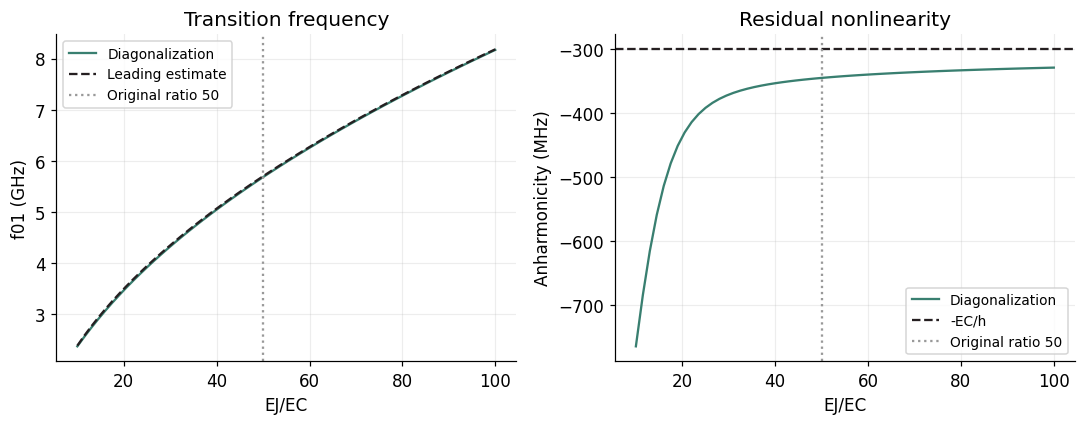

In [12]:
ratios = np.linspace(10, 100, 61)
sweep = np.array([transitions(ej=r*EC) for r in ratios])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ratios, sweep[:, 0], color=TEAL, label="Diagonalization")
axes[0].plot(ratios, np.sqrt(8*ratios)*EC-EC, "--", color=INK, label="Leading estimate")
axes[0].set(xlabel="EJ/EC", ylabel="f01 (GHz)", title="Transition frequency")
axes[1].plot(ratios, sweep[:, 1]*1e3, color=TEAL, label="Diagonalization")
axes[1].axhline(-EC*1e3, linestyle="--", color=INK, label="-EC/h")
axes[1].set(xlabel="EJ/EC", ylabel="Anharmonicity (MHz)", title="Residual nonlinearity")
for ax in axes:
    ax.axvline(EJ/EC, color="0.6", linestyle=":", label="Original ratio 50")
    ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

## 5. Circuit parameters implied by the example
We convert the chosen EC and EJ to **implied lumped circuit parameters**, not extracted geometry. $C_\Sigma$ includes all capacitance relevant to the chosen single mode, including the junction capacitance if present. $L_J$ below is the small-signal junction inductance around zero phase; the simulated Hamiltonian retains the nonlinear cosine.

In [13]:
C_sigma = e**2/(2*h*EC*1e9)
EJ_joules = h*EJ*1e9
phi0 = h/(2*e)
Ic = 2*np.pi*EJ_joules/phi0
LJ = (phi0/(2*np.pi))**2/EJ_joules
print(f"C_sigma implied by EC/h: {C_sigma*1e15:.4f} fF")
print(f"Critical current implied by EJ/h: {Ic*1e9:.4f} nA")
print(f"Small-signal LJ: {LJ*1e9:.4f} nH")
print(f"Harmonic LC frequency: {1/(2*np.pi*np.sqrt(LJ*C_sigma))/1e9:.6f} GHz")
print("These are derived from chosen energies, not EM-extracted values.")

C_sigma implied by EC/h: 64.5674 fF
Critical current implied by EJ/h: 30.2003 nA
Small-signal LJ: 10.8974 nH
Harmonic LC frequency: 6.000000 GHz
These are derived from chosen energies, not EM-extracted values.


## 6. Two-dimensional electrostatic teaching model
**This section is not a chip simulation.** Two zero-thickness strip conductors in a homogeneous vacuum cross-section are held at +0.5 V and -0.5 V. The outer box is grounded. Geometry is invariant along the omitted depth direction. There is no substrate, junction, readout, packaging or finite pad length.

We solve $\nabla^2 V=0$ on a square grid using a sparse five-point finite-difference stencil. The field is $\mathbf E=-\nabla V$. For a 1 V differential drive, the energy-equivalent capacitance per unit depth is
$$C'_{diff}=\frac{2U'}{(\Delta V)^2},\qquad U'=\frac{\epsilon_0}{2}\int |\nabla V|^2 dA.$$

The code evaluates discrete energy on grid edges. A separate conductor-charge calculation checks that $2U'=\sum_i V_iQ'_i$. With symmetric differential drive and zero net common-mode charge, $C'_{diff}=Q'_+/(V_+-V_-)$. This includes the grounded box's effect; it is not an isolated mutual-capacitance matrix element. Units are **F/m**, not F. We do not multiply by an arbitrary depth to claim a real pad capacitance.

Illustrative dimensions: each strip spans x = [-150, -30] or [30, 150] micrometers at y = 0; gap = 60 micrometers; initial box spans ±300 micrometers. All strip endpoints lie on every tested grid.

In [14]:
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

def solve_cross_section(step_um=5, halfbox_um=300):
    # Uniform grid; square cells; SI conversions only where derivatives need length.
    x_um = np.arange(-halfbox_um, halfbox_um + step_um/2, step_um)
    y_um = x_um.copy()
    X_um, Y_um = np.meshgrid(x_um, y_um)
    shape = X_um.shape
    row0 = np.argmin(abs(y_um))
    plus = np.zeros(shape, bool); minus = plus.copy()
    plus[row0, :] = (x_um >= -150) & (x_um <= -30)
    minus[row0, :] = (x_um >= 30) & (x_um <= 150)
    fixed = plus | minus
    fixed[0, :] = fixed[-1, :] = True
    fixed[:, 0] = fixed[:, -1] = True
    V = np.zeros(shape); V[plus] = 0.5; V[minus] = -0.5
    unknown = ~fixed
    idx = np.full(shape, -1, dtype=int)
    idx[unknown] = np.arange(unknown.sum())
    rr, cc, data = [], [], []
    b = np.zeros(unknown.sum())
    for j, i in np.argwhere(unknown):
        k = idx[j, i]
        rr.append(k); cc.append(k); data.append(4.)
        for jj, ii in ((j-1,i),(j+1,i),(j,i-1),(j,i+1)):
            if fixed[jj, ii]: b[k] += V[jj, ii]
            else:
                rr.append(k); cc.append(idx[jj, ii]); data.append(-1.)
    A = coo_matrix((data, (rr, cc)), shape=(len(b),len(b))).tocsr()
    V[unknown] = spsolve(A, b)
    residual = np.max(np.abs(A @ V[unknown] - b))
    # Each square-grid edge contributes eps*(delta V)^2 to 2U' (F/m * V²).
    twice_energy = epsilon_0 * (np.sum(np.diff(V,axis=0)**2) + np.sum(np.diff(V,axis=1)**2))
    q_plus = 0.0
    for j, i in np.argwhere(plus):
        for jj, ii in ((j-1,i),(j+1,i),(j,i-1),(j,i+1)):
            if not plus[jj,ii]: q_plus += epsilon_0*(V[j,i]-V[jj,ii])
    d = step_um*1e-6
    dVdy, dVdx = np.gradient(V, d, d)
    return dict(x=x_um, y=y_um, V=V, Ex=-dVdx, Ey=-dVdy,
                plus=plus, minus=minus, Cprime=twice_energy, Qplus=q_plus,
                residual=residual, step_um=step_um, halfbox_um=halfbox_um)

em = solve_cross_section()
print(f"Grid: {em['V'].shape}, step = {em['step_um']} um")
print(f"Discrete Laplace residual: {em['residual']:.3e} V")
print(f"Differential C' from energy: {em['Cprime']:.6e} F/m")
print(f"Differential C' from charge: {em['Qplus']:.6e} F/m (Delta V = 1 V)")
print(f"Energy/charge relative mismatch: {abs(em['Cprime']/em['Qplus']-1):.3e}")
assert em['residual'] < 1e-9
assert abs(em['Cprime']/em['Qplus']-1) < 1e-8
assert np.max(abs(em['V'])) <= 0.5+1e-10
assert np.max(abs(em['V'] + em['V'][:, ::-1])) < 1e-9

Grid: (121, 121), step = 5 um
Discrete Laplace residual: 2.442e-15 V
Differential C' from energy: 1.866353e-11 F/m
Differential C' from charge: 1.866353e-11 F/m (Delta V = 1 V)
Energy/charge relative mismatch: 4.330e-15


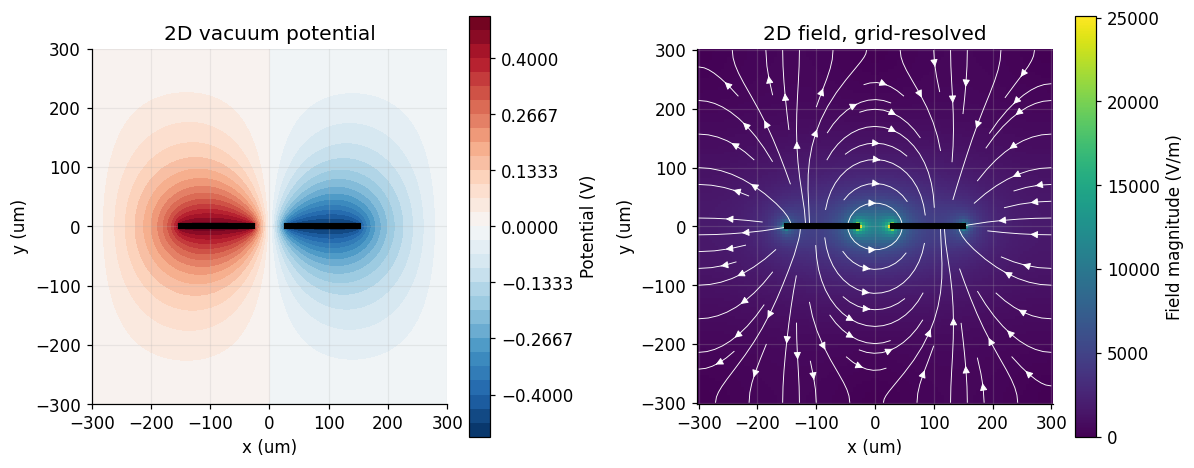

Strip-edge fields depend on grid resolution; do not interpret the maximum as a physical breakdown field.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
X, Y = np.meshgrid(em['x'], em['y'])
p = axes[0].contourf(X, Y, em['V'], levels=np.linspace(-.5,.5,31), cmap="RdBu_r")
fig.colorbar(p, ax=axes[0], label="Potential (V)")
E_mag = np.hypot(em['Ex'], em['Ey'])
# Mask conductors: a perfect conductor has no interior field to interpret here.
E_plot = np.ma.array(E_mag, mask=em['plus']|em['minus'])
p = axes[1].pcolormesh(X, Y, E_plot, shading="auto", cmap="viridis")
fig.colorbar(p, ax=axes[1], label="Field magnitude (V/m)")
axes[1].streamplot(em['x'], em['y'], em['Ex'], em['Ey'], color="white", density=0.75, linewidth=.6)
for ax, title in zip(axes, ["2D vacuum potential", "2D field, grid-resolved"]):
    ax.plot([-150,-30],[0,0],color="black",lw=4)
    ax.plot([30,150],[0,0],color="black",lw=4)
    ax.set(xlabel="x (um)", ylabel="y (um)", title=title, aspect="equal")
fig.tight_layout(); plt.show()
print("Strip-edge fields depend on grid resolution; do not interpret the maximum as a physical breakdown field.")

### Grid and box-size checks
We first refine the mesh at fixed box size, then enlarge the box at fixed grid step. These are sensitivity checks, not proof of continuum or open-boundary convergence. Sharp zero-thickness strip edges slow convergence. A grounded finite box changes the physical boundary condition, so we report the residual box sensitivity.

In [16]:
em_checks = []
print("Grid study at half-box 300 um")
for step in [10, 5, 2.5]:
    result = em if step == 5 else solve_cross_section(step_um=step)
    em_checks.append(("grid",step,300,result['Cprime']))
    print(f"step {step:4.1f} um: C' = {result['Cprime']:.6e} F/m")
grid_change = abs(em_checks[-1][3]/em_checks[-2][3]-1)*100
print(f"Last refinement change: {grid_change:.3f}%")
print("\nBox study at step 5 um")
for box in [300, 450, 600]:
    result = em if box == 300 else solve_cross_section(halfbox_um=box)
    em_checks.append(("box",5,box,result['Cprime']))
    print(f"half-box {box:3d} um: C' = {result['Cprime']:.6e} F/m")
box_change = abs(em_checks[-1][3]/em_checks[-2][3]-1)*100
print(f"Last box enlargement change: {box_change:.3f}%")
print("No real-device capacitance is inferred from this study.")

Grid study at half-box 300 um
step 10.0 um: C' = 1.914015e-11 F/m
step  5.0 um: C' = 1.866353e-11 F/m


step  2.5 um: C' = 1.843259e-11 F/m
Last refinement change: 1.237%

Box study at step 5 um
half-box 300 um: C' = 1.866353e-11 F/m
half-box 450 um: C' = 1.782047e-11 F/m


half-box 600 um: C' = 1.755920e-11 F/m
Last box enlargement change: 1.466%
No real-device capacitance is inferred from this study.


## 7. From an actual capacitance extraction to EC
A free route documented by Quantum Metal is **layout → Gmsh mesh → Elmer electrostatic solve → Maxwell capacitance matrix → circuit reduction → EC → scqubits**. ElmerSolver and ElmerGrid are separate external programs, not installed by a Python import. The linked tutorial is an external workflow reference, **not a solver run completed in this notebook**.

For a single island referenced to ground, we use the total effective node capacitance $C_\Sigma$. For a floating two-pad device with only pad-to-ground capacitances $C_{1g},C_{2g}$ and mutual capacitance $C_m$, eliminating the floating common coordinate at fixed total charge gives
$$C_{eff}=C_m+\frac{C_{1g}C_{2g}}{C_{1g}+C_{2g}}.$$
We add the junction capacitance across the pads if the EM model omitted it. This simple formula assumes other conductors have already been treated correctly; it should not be applied blindly to a readout-coupled multi-node matrix. A Maxwell matrix has nonpositive off-diagonal elements: a positive mutual capacitance is $C_m=-C_{12}$, not $C_{12}$. We state the conductor ordering, reference, units, and any eliminated nodes.

**Before we call a result extracted:** we must specify pad/ground geometry, substrate and permittivity, metal model, junction and readout treatment, boundary conditions, independent mesh and box convergence, and matrix units/sign convention. We also check matrix symmetry, energy positivity and physical node mapping. None of those real-device inputs has been supplied here. We keep chosen-energy circuit parameters and extracted values in separate tables.

The next cell demonstrates the conversion using a **synthetic floating two-pad circuit**. Its arbitrary 50 fF and 15 fF values are not an extraction and deliberately do not replace our base 0.30 GHz EC.

In [17]:
def EC_from_capacitance(C_fF):
    if not np.isfinite(C_fF) or C_fF <= 0:
        raise ValueError("Effective capacitance must be finite and positive, in fF")
    return e**2/(2*h*C_fF*1e-15)/1e9

# SYNTHETIC circuit, not solver output. Two pads, ground excluded from matrix.
C1g_fF, C2g_fF, Cm_fF, Cj_fF = 50., 50., 15., 2.
Cmaxwell_fF = np.array([[C1g_fF+Cm_fF, -Cm_fF],
                        [-Cm_fF, C2g_fF+Cm_fF]])
assert np.allclose(Cmaxwell_fF, Cmaxwell_fF.T)
assert np.linalg.eigvalsh(Cmaxwell_fF).min() > 0
Ceff_fF = Cm_fF + C1g_fF*C2g_fF/(C1g_fF+C2g_fF) + Cj_fF
synthetic_EC = EC_from_capacitance(Ceff_fF)
synthetic_f, synthetic_alpha = transitions(ec=synthetic_EC)
print("SYNTHETIC Maxwell matrix, fF (junction excluded):\n", Cmaxwell_fF)
print(f"Floating differential C_eff including junction: {Ceff_fF:.3f} fF")
print(f"Synthetic EC/h: {synthetic_EC:.6f} GHz")
print(f"At original EJ/h=15 GHz: f01={synthetic_f:.6f} GHz, alpha={synthetic_alpha*1000:.3f} MHz")
assert abs(EC_from_capacitance(C_sigma*1e15)-EC) < 1e-12
print("PASS: capacitance/EC round-trip units check.")

SYNTHETIC Maxwell matrix, fF (junction excluded):
 [[ 65. -15.]
 [-15.  65.]]
Floating differential C_eff including junction: 42.000 fF
Synthetic EC/h: 0.461196 GHz
At original EJ/h=15 GHz: f01=6.943661 GHz, alpha=-560.515 MHz
PASS: capacitance/EC round-trip units check.


### 7b. Link to Module 1: a coplanar-waveguide (CPW) readout resonator as a transmission line
A transmon is read out through a microwave resonator, which is a transmission line. This ties the qubit work to Module 1 (characteristic impedance, input impedance, reflection coefficient, VSWR). The CPW formulas below are the standard conformal-mapping results for zero-thickness metal on an infinitely thick substrate. Dimensions are **illustrative**, not from our design.

$$\varepsilon_{eff}=\frac{1+\varepsilon_r}{2},\qquad Z_0=\frac{30\pi}{\sqrt{\varepsilon_{eff}}}\,\frac{K(k')}{K(k)},\quad k=\frac{s}{s+2w},\; k'=\sqrt{1-k^2},$$
$$Z_{in}=jZ_0\tan(\beta\ell)\ \text{for a line shorted at the far end,}\qquad \Gamma=\frac{Z_L-Z_0}{Z_L+Z_0},\quad \mathrm{VSWR}=\frac{1+|\Gamma|}{1-|\Gamma|}.$$

CPW (s = 10 um, w = 6 um, eps_r = 11.45): Z0 = 50.94 ohm, eps_eff = 6.225
Quarter-wave length for 7.0 GHz: 4.291 mm
Peaks of |Zin| (GHz): [ 7. 21.] (expected f0, 3 f0, ... =  [ 7. 21. 35.] )


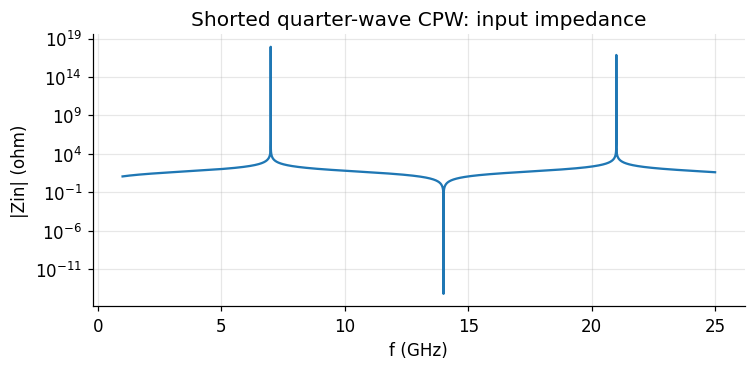

ZL = 50.0: Gamma = -0.009, |Gamma| = 0.009, VSWR = 1.019, round-trip |Gamma| check = 0.009
ZL = 100.0: Gamma = 0.325, |Gamma| = 0.325, VSWR = 1.963, round-trip |Gamma| check = 0.325
ZL = 25.0: Gamma = -0.342, |Gamma| = 0.342, VSWR = 2.037, round-trip |Gamma| check = 0.342
ZL = (50+50j): Gamma = 0.190+0.401j, |Gamma| = 0.444, VSWR = 2.597, round-trip |Gamma| check = 0.444
Z0 differs from 50 ohm by +0.94 ohm for these dimensions: a real design tunes s and w to match the feedline.
PASS: resonances at f0 and 3 f0 as the quarter-wave theory predicts; Gamma/VSWR round trip is exact.


In [18]:
from scipy.special import ellipk
def cpw(s_um, w_um, eps_r):
    k = s_um/(s_um + 2*w_um); kp = np.sqrt(1 - k**2)
    eeff = (1 + eps_r)/2
    Z0 = 30*np.pi/np.sqrt(eeff)*ellipk(kp**2)/ellipk(k**2)
    return Z0, eeff
Z0, eeff = cpw(10.0, 6.0, 11.45)       # centre strip 10 um, gaps 6 um (illustrative)
c0 = 299792458.0
f_target = 7.0e9                        # ASSUMED example readout frequency
length = c0/(4*f_target*np.sqrt(eeff))
print(f"CPW (s = 10 um, w = 6 um, eps_r = 11.45): Z0 = {Z0:.2f} ohm, eps_eff = {eeff:.3f}")
print(f"Quarter-wave length for {f_target/1e9:.1f} GHz: {length*1e3:.3f} mm")

# Input impedance of the shorted line vs frequency (Module 1): resonances where |Zin| peaks
f = np.linspace(1e9, 25e9, 48001)
beta = 2*np.pi*f*np.sqrt(eeff)/c0
Zin = 1j*Z0*np.tan(beta*length)
mag = np.abs(Zin)
pk = [i for i in range(1, len(f) - 1) if mag[i] > mag[i-1] and mag[i] > mag[i+1] and mag[i] > 50*Z0]
f_res = f[pk]
print("Peaks of |Zin| (GHz):", np.round(f_res/1e9, 3), "(expected f0, 3 f0, ... = ", np.round(f_target*np.array([1, 3, 5])/1e9, 3), ")")
assert abs(f_res[0] - f_target)/f_target < 1e-3 and abs(f_res[1] - 3*f_target)/(3*f_target) < 1e-3
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.semilogy(f/1e9, mag); ax.set_xlabel('f (GHz)'); ax.set_ylabel('|Zin| (ohm)'); ax.set_title('Shorted quarter-wave CPW: input impedance'); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

# Reflection coefficient and VSWR for a mismatched termination (Smith-chart quantities in Module 1)
for ZL in (50.0, 100.0, 25.0, 50.0 + 50.0j):
    G = (ZL - Z0)/(ZL + Z0); vswr = (1 + abs(G))/(1 - abs(G))
    G_back = (vswr - 1)/(vswr + 1)
    print(f"ZL = {ZL}: Gamma = {G:.3f}, |Gamma| = {abs(G):.3f}, VSWR = {vswr:.3f}, round-trip |Gamma| check = {G_back:.3f}")
    assert abs(abs(G) - G_back) < 1e-12
print(f"Z0 differs from 50 ohm by {Z0 - 50:+.2f} ohm for these dimensions: a real design tunes s and w to match the feedline.")
print("PASS: resonances at f0 and 3 f0 as the quarter-wave theory predicts; Gamma/VSWR round trip is exact.")

## 8. Results and interpretation
The next table is generated from the calculation, so it updates if we change the base parameters and rerun. Our notebook does not model driven gates, readout coupling, material losses or fabrication.

In [19]:
summary = [
    ("EJ/h (chosen)", EJ, "GHz"), ("EC/h (chosen)", EC, "GHz"),
    ("EJ/EC", EJ/EC, "dimensionless"), ("f01 (diagonalized)", f01, "GHz"),
    ("f12 (diagonalized)", f12, "GHz"),
    ("alpha (diagonalized)", anharmonicity*1000, "MHz"),
    ("C_sigma implied by chosen EC", C_sigma*1e15, "fF"),
    ("LJ implied by chosen EJ", LJ*1e9, "nH"),
    ("f01 charge dispersion at ratio 50", dispersions[50], "Hz"),
    ("2D teaching C' (5 um grid)", em['Cprime']*1e12, "pF/m"),
    ("Last 2D grid-refinement change", grid_change, "%"),
    ("Last 2D box-enlargement change", box_change, "%")]
rows = "\n".join(f"| {label} | {value:.6g} | {unit} |" for label,value,unit in summary)
display(Markdown("| Quantity | Value | Unit |\n|---|---:|---|\n"+rows))
print("\nChecks passed: independent Hamiltonian, quantum cutoff, state normalization,")
print("Laplace residual, potential bound, antisymmetry, energy/charge agreement, EC round trip.")
print("Scientific status: simulated illustrative model, not experimentally validated device.")

| Quantity | Value | Unit |
|---|---:|---|
| EJ/h (chosen) | 15 | GHz |
| EC/h (chosen) | 0.3 | GHz |
| EJ/EC | 50 | dimensionless |
| f01 (diagonalized) | 5.68258 | GHz |
| f12 (diagonalized) | 5.33781 | GHz |
| alpha (diagonalized) | -344.767 | MHz |
| C_sigma implied by chosen EC | 64.5674 | fF |
| LJ implied by chosen EJ | 10.8974 | nH |
| f01 charge dispersion at ratio 50 | 11889.1 | Hz |
| 2D teaching C' (5 um grid) | 18.6635 | pF/m |
| Last 2D grid-refinement change | 1.2374 | % |
| Last 2D box-enlargement change | 1.46614 | % |


Checks passed: independent Hamiltonian, quantum cutoff, state normalization,
Laplace residual, potential bound, antisymmetry, energy/charge agreement, EC round trip.
Scientific status: simulated illustrative model, not experimentally validated device.


### Conclusions
- Our base parameters give unequal transition spacings and negative anharmonicity, consistent with a transmon rather than a harmonic oscillator.
- The independent charge-basis calculation and cutoff test check the numerical spectrum. The offset-charge sweep demonstrates reduced charge sensitivity at the higher EJ/EC ratio.
- EC connects quantum behavior to the effective circuit capacitance. Inferring capacitance from a chosen EC is the reverse of a device extraction.
- The 2D model connects potential, electric field, stored energy and capacitance per unit depth.

### Sources
1. [scqubits: Transmon guide](https://scqubits.readthedocs.io/en/latest/guide/qubits/transmon.html). Charge-basis Hamiltonian, ncut and spectrum/wavefunction API. Checked 27 October 2026. The execution below uses 4.3.1, not an unspecified latest release.
2. [Koch et al., Charge insensitive qubit design derived from the Cooper pair box (2007)](https://arxiv.org/abs/cond-mat/0703002). Transmon regime and charge-dispersion/anharmonicity tradeoff. Phys. Rev. A 76, 042319.
3. [Quantum Metal tutorial 4.19: transmon using ElmerFEM](https://qiskit-community.github.io/qiskit-metal/tut/4-Analysis/4.19-Analyze-a-transmon-using-ElmerFEM.html). Free meshing, capacitance-matrix and lumped-oscillator route. This is a reference for our later 3D work, not a completed run here.
4. [Quantum Metal open FEM stack installation notes](https://github.com/qiskit-community/qiskit-metal/blob/main/README_Open_FEM_Stack.md). Elmer binaries are installed separately from Python packages. Checked 27 October 2026.

We wrote the 2D finite-difference code and the synthetic circuit reduction as self-contained implementations of the equations stated above.